In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/bank.csv")
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


Understanding the dataset

In [4]:
#Column names
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'deposit'],
      dtype='object')

In [5]:
#First 5 records
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [6]:
#Information about the data set
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11162 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.4+ MB


In [7]:
#last 5 records
df.tail()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
11157,33,blue-collar,single,primary,no,1,yes,no,cellular,20,apr,257,1,-1,0,unknown,no
11158,39,services,married,secondary,no,733,no,no,unknown,16,jun,83,4,-1,0,unknown,no
11159,32,technician,single,secondary,no,29,no,no,cellular,19,aug,156,2,-1,0,unknown,no
11160,43,technician,married,secondary,no,0,no,yes,cellular,8,may,9,2,172,5,failure,no
11161,34,technician,married,secondary,no,0,no,no,cellular,9,jul,628,1,-1,0,unknown,no


In [8]:
#Statistical information about the data
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000
mean,41.231948,1528.538524,15.658036,371.993818,2.508421,51.330407,0.832557
std,11.913369,3225.413326,8.420740,347.128386,2.722077,108.758282,2.292007
min,18.000000,-6847.000000,1.000000,2.000000,1.000000,-1.000000,0.000000
25%,32.000000,122.000000,8.000000,138.000000,1.000000,-1.000000,0.000000
50%,39.000000,550.000000,15.000000,255.000000,2.000000,-1.000000,0.000000
75%,49.000000,1708.000000,22.000000,496.000000,3.000000,20.750000,1.000000
max,95.000000,81204.000000,31.000000,3881.000000,63.000000,854.000000,58.000000


In [9]:
df.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


Finiding records and attributes

In [10]:
# Find the number of records and attributes

print("Number of records:", df.shape[0])
print("Number of attributes:", df.shape[1])

Number of records: 11162
Number of attributes: 17


Identify numerical attributes

In [11]:
numerical_columns = df.select_dtypes(include=np.number).columns

print("Numerical Attributes:")
print(list(numerical_columns))

# View only numerical data
df[numerical_columns].head()

Numerical Attributes:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


,age,balance,day,duration,campaign,pdays,previous
0,59,2343,5,1042,1,-1,0
1,56,45,5,1467,1,-1,0
2,41,1270,5,1389,1,-1,0
3,55,2476,5,579,1,-1,0
4,54,184,5,673,2,-1,0


Identify categorical attributes

In [12]:
categorical_columns = df.select_dtypes(
    include=['object', 'category']
).columns

print("Categorical Attributes:")
print(list(categorical_columns))

Categorical Attributes:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'deposit']


Numerical Analysis

In [14]:
df[numerical_columns].describe()

,age,balance,day,duration,campaign,pdays,previous
count,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000
mean,41.231948,1528.538524,15.658036,371.993818,2.508421,51.330407,0.832557
std,11.913369,3225.413326,8.420740,347.128386,2.722077,108.758282,2.292007
min,18.000000,-6847.000000,1.000000,2.000000,1.000000,-1.000000,0.000000
25%,32.000000,122.000000,8.000000,138.000000,1.000000,-1.000000,0.000000
50%,39.000000,550.000000,15.000000,255.000000,2.000000,-1.000000,0.000000
75%,49.000000,1708.000000,22.000000,496.000000,3.000000,20.750000,1.000000
max,95.000000,81204.000000,31.000000,3881.000000,63.000000,854.000000,58.000000


In [16]:
# Average age of customers
print("Average Age:", df['age'].mean())

# Average account balance
print("Average Balance:", df['balance'].mean())

# Maximum account balance
print("Maximum Balance:", df['balance'].max())

# Average contact duration
print("Average Duration:", df['duration'].mean())

# Maximum campaign contacts
print("Maximum Campaign Contacts:", df['campaign'].max())

Average Age: 41.231947679627304
Average Balance: 1528.5385235620856
Maximum Balance: 81204
Average Duration: 371.99381831213043
Maximum Campaign Contacts: 63


Univariate Analysis

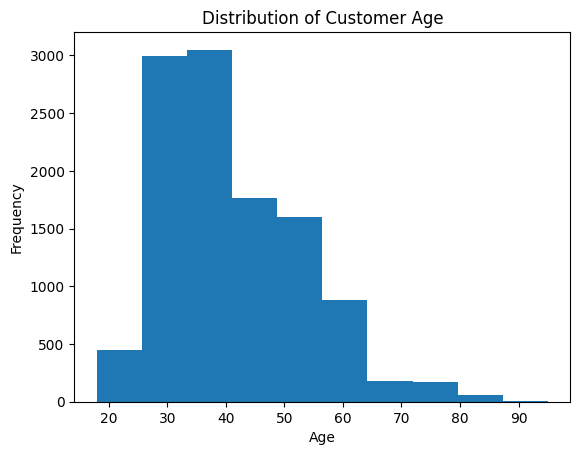

In [17]:
# Histogram of Age

plt.hist(df['age'])

plt.title('Distribution of Customer Age')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.show()

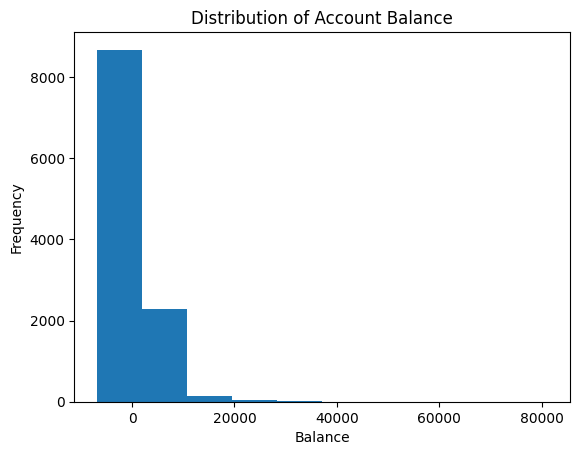

In [18]:
# Histogram of Account Balance

plt.hist(df['balance'])

plt.title('Distribution of Account Balance')
plt.xlabel('Balance')
plt.ylabel('Frequency')

plt.show()

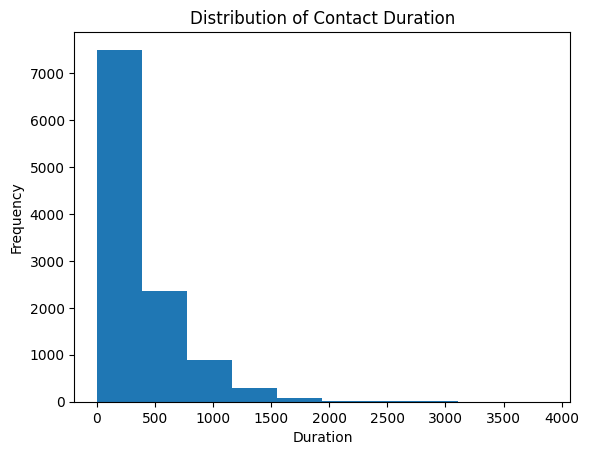

In [19]:
# Histogram of Duration

plt.hist(df['duration'])

plt.title('Distribution of Contact Duration')
plt.xlabel('Duration')
plt.ylabel('Frequency')

plt.show()

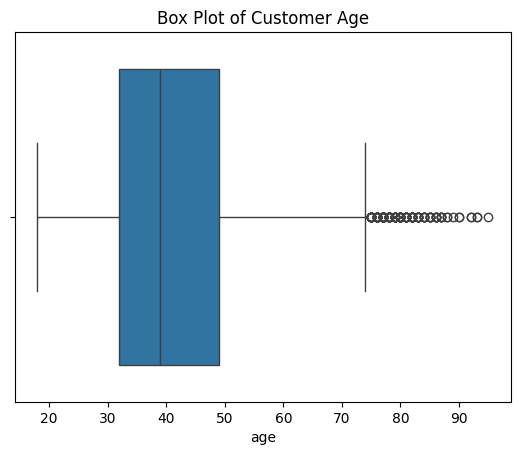

In [20]:
# Box plot of Age

sns.boxplot(x=df['age'])

plt.title('Box Plot of Customer Age')

plt.show()

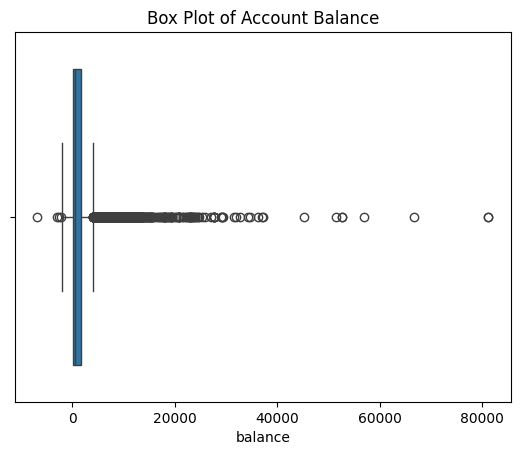

In [21]:
# Box plot of Account Balance

sns.boxplot(x=df['balance'])

plt.title('Box Plot of Account Balance')

plt.show()

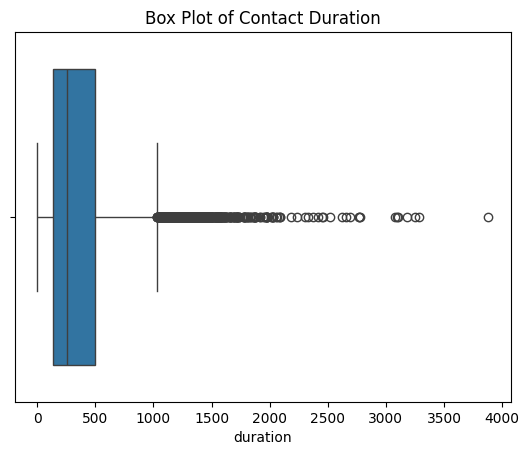

In [22]:
# Box plot of Duration

sns.boxplot(x=df['duration'])

plt.title('Box Plot of Contact Duration')

plt.show()

Bivariate Analysis

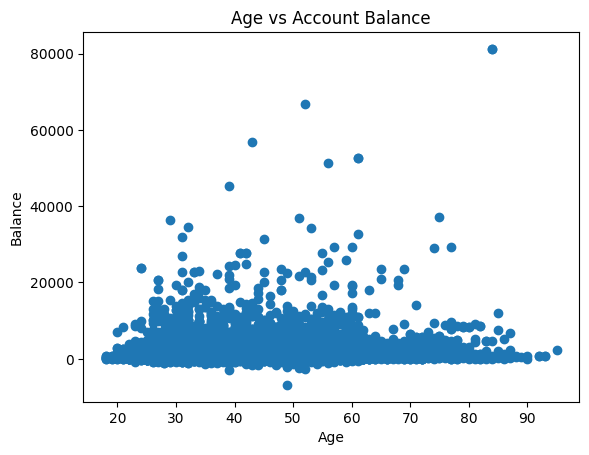

In [23]:
# Age vs Balance

plt.scatter(df['age'], df['balance'])

plt.title('Age vs Account Balance')
plt.xlabel('Age')
plt.ylabel('Balance')

plt.show()

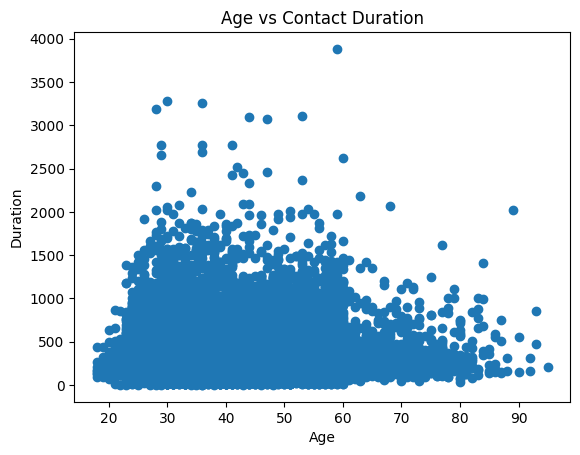

In [24]:
# Age vs Duration

plt.scatter(df['age'], df['duration'])

plt.title('Age vs Contact Duration')
plt.xlabel('Age')
plt.ylabel('Duration')

plt.show()

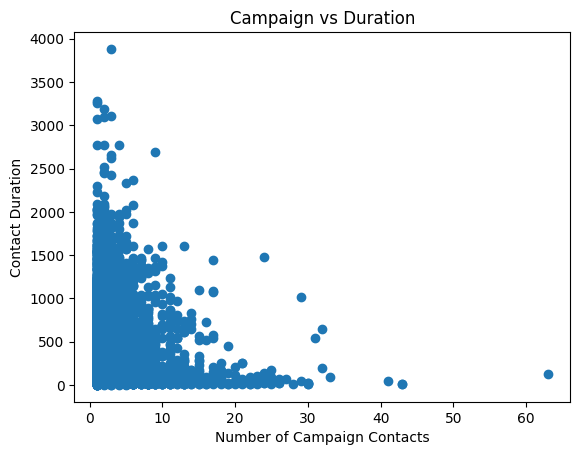

In [25]:
# Campaign vs Duration

plt.scatter(df['campaign'], df['duration'])

plt.title('Campaign vs Duration')
plt.xlabel('Number of Campaign Contacts')
plt.ylabel('Contact Duration')

plt.show()

In [26]:
# Correlation between Age and Balance

correlation = df['age'].corr(df['balance'])

print("Correlation between Age and Balance:", correlation)

Correlation between Age and Balance: 0.11229988859873165


In [27]:
# Correlation between Campaign and Duration

correlation = df['campaign'].corr(df['duration'])

print("Correlation between Campaign and Duration:", correlation)

Correlation between Campaign and Duration: -0.04155745875962314


Multivariate Analysis

In [28]:
# Correlation among multiple numerical variables

correlation_matrix = df.corr(numeric_only=True)

print(correlation_matrix)

               age   balance       day  duration  campaign     pdays  previous
age       1.000000  0.112300 -0.000762  0.000189 -0.005278  0.002774  0.020169
balance   0.112300  1.000000  0.010467  0.022436 -0.013894  0.017411  0.030805
day      -0.000762  0.010467  1.000000 -0.018511  0.137007 -0.077232 -0.058981
duration  0.000189  0.022436 -0.018511  1.000000 -0.041557 -0.027392 -0.026716
campaign -0.005278 -0.013894  0.137007 -0.041557  1.000000 -0.102726 -0.049699
pdays     0.002774  0.017411 -0.077232 -0.027392 -0.102726  1.000000  0.507272
previous  0.020169  0.030805 -0.058981 -0.026716 -0.049699  0.507272  1.000000


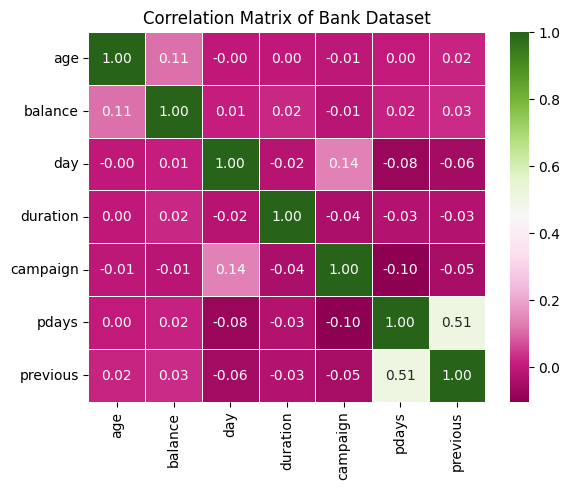

In [29]:
# Correlation Heatmap

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='PiYG',
    fmt=".2f",
    linewidths=0.5
)

plt.title('Correlation Matrix of Bank Dataset')

plt.show()

Number of outliers: 1055


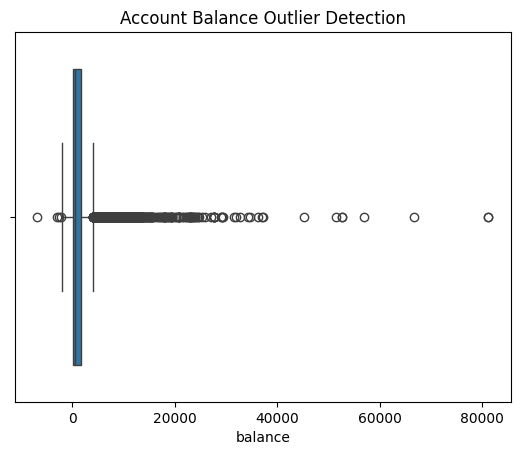

In [30]:
# Outlier Detection Using IQR

Q1 = df['balance'].quantile(0.25)

Q3 = df['balance'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

# Identify outliers

outliers = df[
    (df['balance'] < lower_limit) |
    (df['balance'] > upper_limit)
]

print("Number of outliers:", len(outliers))

# Visualise outliers

sns.boxplot(x=df['balance'])

plt.title('Account Balance Outlier Detection')

plt.show()

In [31]:
Q1 = df['duration'].quantile(0.25)
Q3 = df['duration'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['duration'] < lower_limit) |
    (df['duration'] > upper_limit)
]

print("Number of Duration Outliers:", len(outliers))

Number of Duration Outliers: 636


Categorical Analysis

In [32]:
# Identify categorical columns

categorical_columns = df.select_dtypes(
    include=['object', 'category']
).columns

print(list(categorical_columns))

['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'deposit']


In [33]:
# Frequency distribution of Job

df['job'].value_counts()

,count
job,
management,2566
blue-collar,1944
technician,1823
admin.,1334
services,923
retired,778
self-employed,405
student,360
unemployed,357


In [34]:
# Frequency distribution of Marital Status

df['marital'].value_counts()

,count
marital,
married,6351
single,3518
divorced,1293


In [35]:
# Frequency distribution of Education

df['education'].value_counts()

,count
education,
secondary,5476
tertiary,3689
primary,1500
unknown,497


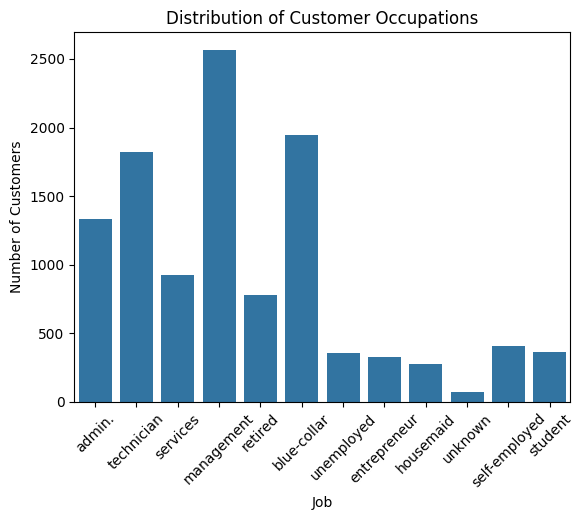

In [36]:
# Count plot of Job

sns.countplot(data=df, x='job')

plt.title('Distribution of Customer Occupations')
plt.xlabel('Job')
plt.ylabel('Number of Customers')

plt.xticks(rotation=45)

plt.show()

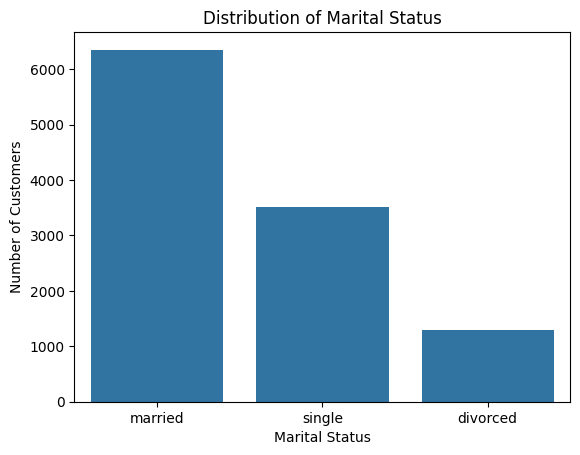

In [37]:
# Count plot of Marital Status

sns.countplot(data=df, x='marital')

plt.title('Distribution of Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Number of Customers')

plt.show()

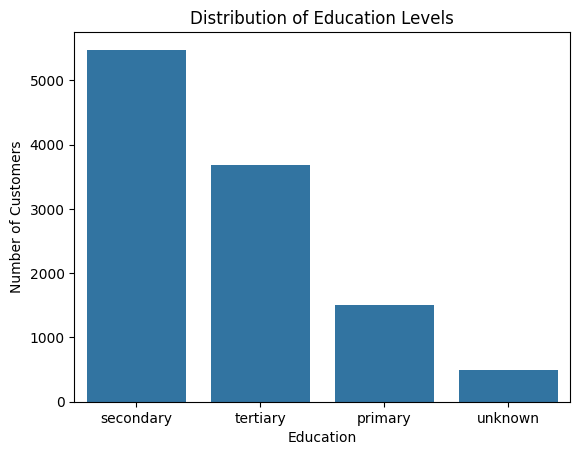

In [38]:
# Count plot of Education

sns.countplot(data=df, x='education')

plt.title('Distribution of Education Levels')
plt.xlabel('Education')
plt.ylabel('Number of Customers')

plt.show()

In [39]:
# Frequency distribution of Deposit

df['deposit'].value_counts()

,count
deposit,
no,5873
yes,5289


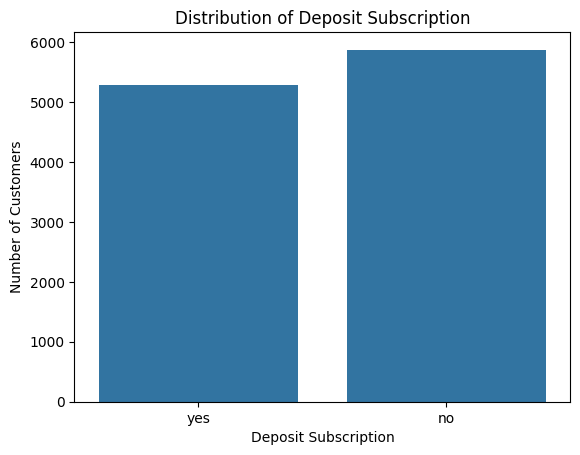

In [40]:
# Count plot of Deposit

sns.countplot(data=df, x='deposit')

plt.title('Distribution of Deposit Subscription')
plt.xlabel('Deposit Subscription')
plt.ylabel('Number of Customers')

plt.show()

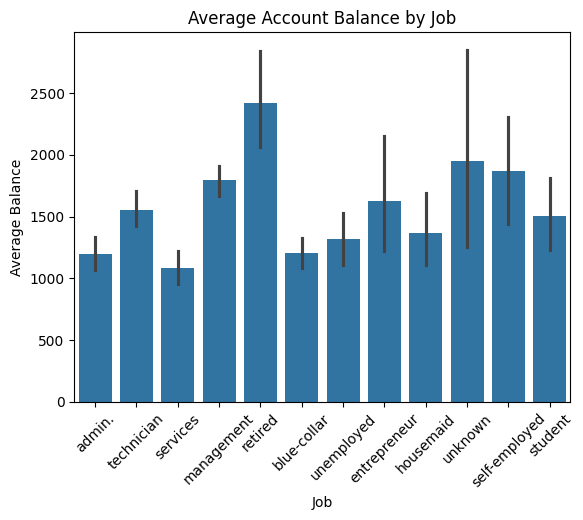

In [41]:
# Job vs Average Balance

sns.barplot(data=df, x='job', y='balance')

plt.title('Average Account Balance by Job')
plt.xlabel('Job')
plt.ylabel('Average Balance')

plt.xticks(rotation=45)

plt.show()

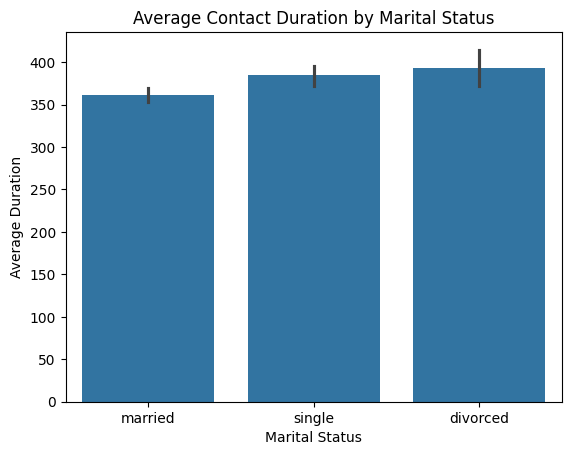

In [42]:
# Marital Status vs Duration

sns.barplot(data=df, x='marital', y='duration')

plt.title('Average Contact Duration by Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Average Duration')

plt.show()

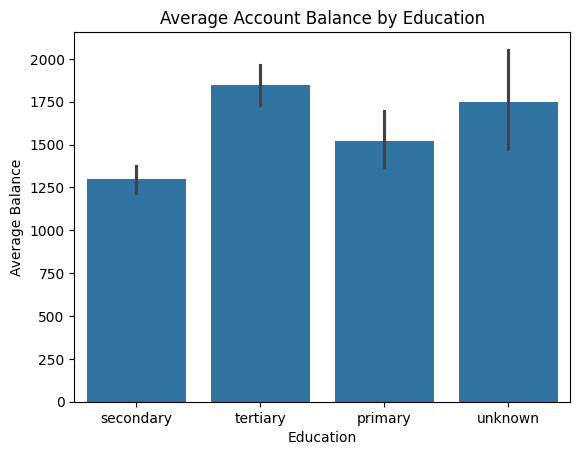

In [43]:
# Education vs Balance

sns.barplot(data=df, x='education', y='balance')

plt.title('Average Account Balance by Education')
plt.xlabel('Education')
plt.ylabel('Average Balance')

plt.show()

Categorical vs Categorical

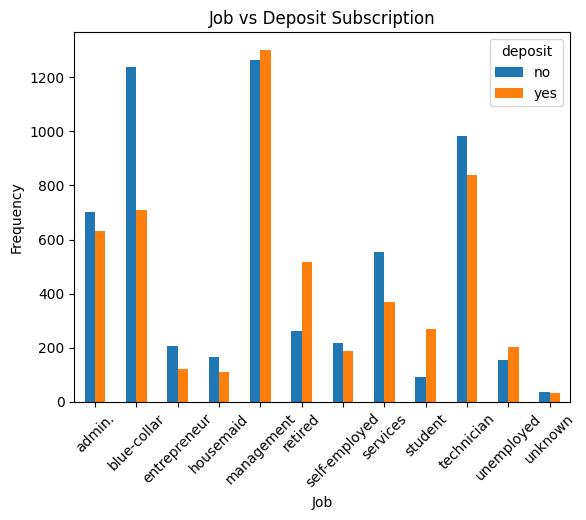

In [44]:
# Job vs Deposit

pd.crosstab(
    df['job'],
    df['deposit']
).plot(kind='bar')

plt.title('Job vs Deposit Subscription')
plt.xlabel('Job')
plt.ylabel('Frequency')

plt.xticks(rotation=45)

plt.show()

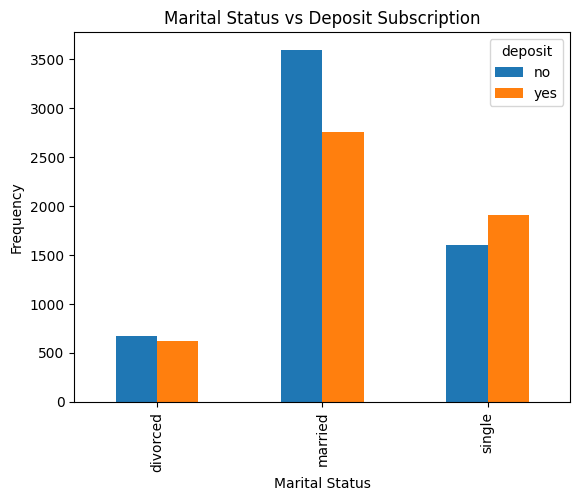

In [45]:
# Marital Status vs Deposit

pd.crosstab(
    df['marital'],
    df['deposit']
).plot(kind='bar')

plt.title('Marital Status vs Deposit Subscription')
plt.xlabel('Marital Status')
plt.ylabel('Frequency')

plt.show()

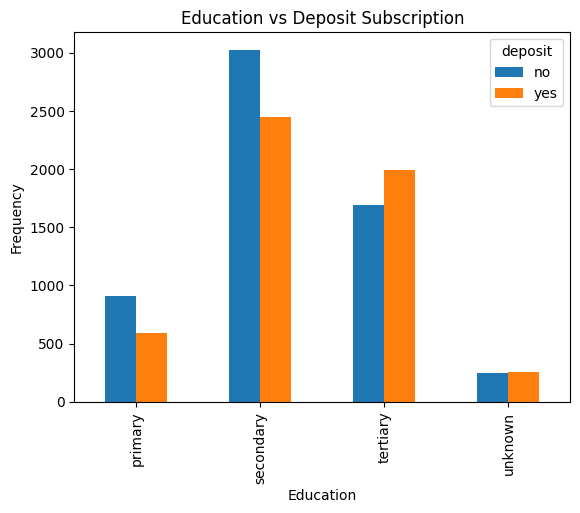

In [46]:
# Education vs Deposit

pd.crosstab(
    df['education'],
    df['deposit']
).plot(kind='bar')

plt.title('Education vs Deposit Subscription')
plt.xlabel('Education')
plt.ylabel('Frequency')

plt.show()

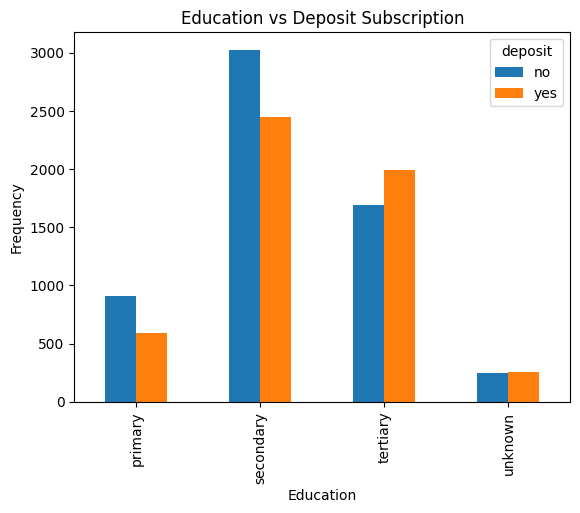

In [47]:
# Education vs Deposit

pd.crosstab(
    df['education'],
    df['deposit']
).plot(kind='bar')

plt.title('Education vs Deposit Subscription')
plt.xlabel('Education')
plt.ylabel('Frequency')

plt.show()

Group by Analysis

In [48]:
# Average Balance by Job

df.groupby('job')['balance'].mean()

,balance
job,
admin.,1195.866567
blue-collar,1203.926440
entrepreneur,1621.942073
housemaid,1366.160584
management,1793.663679
retired,2417.250643
self-employed,1865.372840
services,1081.171181
student,1500.783333


In [49]:
# Total Balance by Marital Status

df.groupby('marital')['balance'].sum()

,balance
marital,
divorced,1773783
married,10161140
single,5126624


In [50]:
# Average Duration by Job

df.groupby('job')['duration'].mean()

,duration
job,
admin.,347.929535
blue-collar,394.658951
entrepreneur,370.182927
housemaid,348.346715
management,361.482073
retired,389.993573
self-employed,396.155556
services,385.955580
student,330.672222


In [51]:
# Total Campaign Contacts by Marital Status

df.groupby('marital')['campaign'].sum()

,campaign
marital,
divorced,3177
married,16649
single,8173


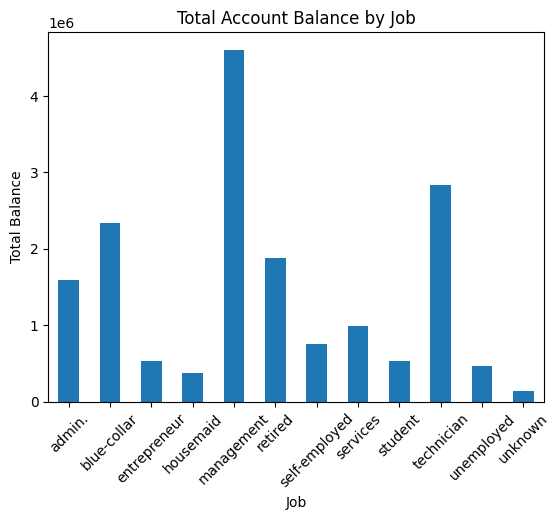

In [52]:
# Total Balance by Job

df.groupby('job')['balance'].sum().plot(
    kind='bar'
)

plt.title('Total Account Balance by Job')
plt.xlabel('Job')
plt.ylabel('Total Balance')

plt.xticks(rotation=45)

plt.show()

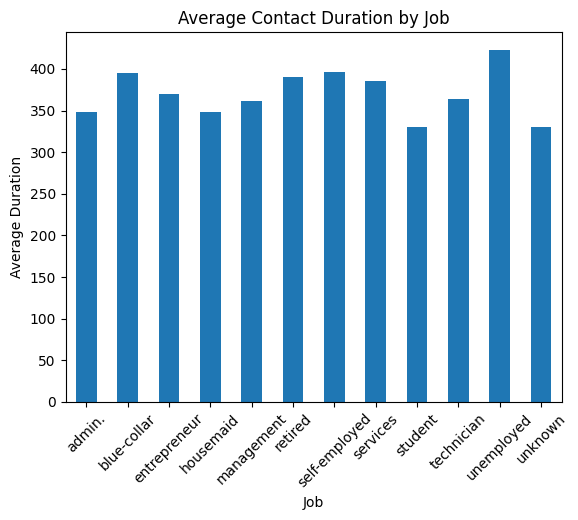

In [53]:
# Average Duration by Job

df.groupby('job')['duration'].mean().plot(
    kind='bar'
)

plt.title('Average Contact Duration by Job')
plt.xlabel('Job')
plt.ylabel('Average Duration')

plt.xticks(rotation=45)

plt.show()

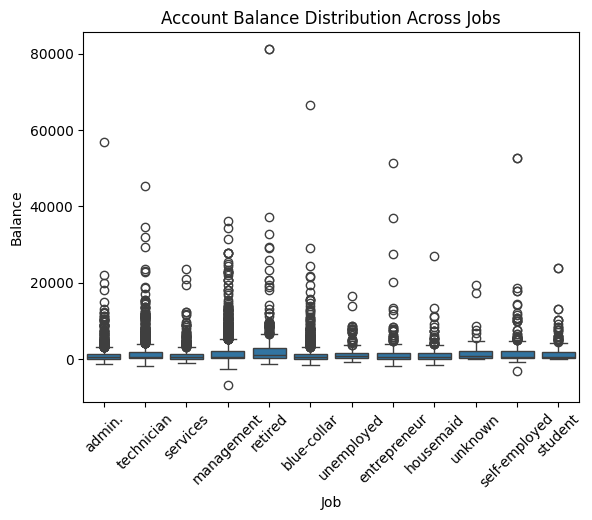

In [54]:
# Job vs Balance

sns.boxplot(
    data=df,
    x='job',
    y='balance'
)

plt.title('Account Balance Distribution Across Jobs')
plt.xlabel('Job')
plt.ylabel('Balance')

plt.xticks(rotation=45)

plt.show()

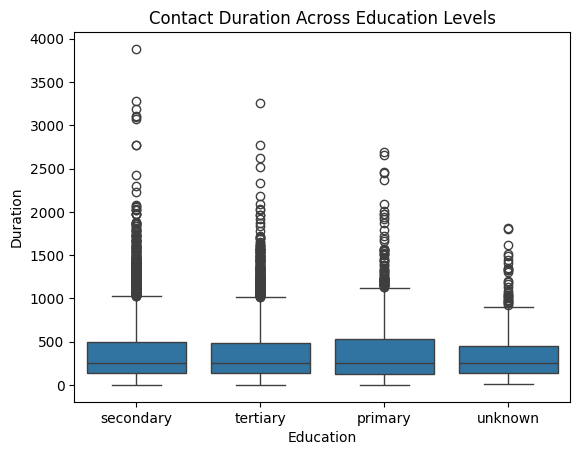

In [55]:
# Education vs Duration

sns.boxplot(
    data=df,
    x='education',
    y='duration'
)

plt.title('Contact Duration Across Education Levels')
plt.xlabel('Education')
plt.ylabel('Duration')

plt.show()

In [57]:
#Which marital category has the highest number of customers?
df['marital'].value_counts()

,count
marital,
married,6351
single,3518
divorced,1293


In [59]:
#Which education category has the highest number of customers?
df['education'].value_counts()

,count
education,
secondary,5476
tertiary,3689
primary,1500
unknown,497


In [60]:
#Which Job Category has highest number of deposit subscriptions
df[df['deposit'] == 'yes']['job'].value_counts()

,count
job,
management,1301
technician,840
blue-collar,708
admin.,631
retired,516
services,369
student,269
unemployed,202
self-employed,187


In [61]:
#which job category has lowwest average account hbalance
df.groupby('job')['balance'].mean().sort_values()

,balance
job,
services,1081.171181
admin.,1195.866567
blue-collar,1203.926440
unemployed,1314.719888
housemaid,1366.160584
student,1500.783333
technician,1556.294569
entrepreneur,1621.942073
management,1793.663679


In [62]:
#Which occupation has average contact duration
df.groupby('job')['duration'].mean().sort_values(ascending=False)

,duration
job,
unemployed,422.843137
self-employed,396.155556
blue-collar,394.658951
retired,389.993573
services,385.955580
entrepreneur,370.182927
technician,363.791552
management,361.482073
housemaid,348.346715


In [63]:
#Compare average account balanvce across matital groupos
df.groupby('marital')['balance'].mean()

,balance
marital,
divorced,1371.835267
married,1599.927570
single,1457.255259


In [64]:
#Compare deposit subscription across education categories.
pd.crosstab(
    df['education'],
    df['deposit']
)

deposit,no,yes
education,,
primary,909,591
secondary,3026,2450
tertiary,1693,1996
unknown,245,252


In [65]:
#Which month has the highest number of customer contacts?
df['month'].value_counts()

,count
month,
may,2824
aug,1519
jul,1514
jun,1222
nov,943
apr,923
feb,776
oct,392
jan,344


In [66]:
#Which previous campaign outcome has the highest frequency?
df['poutcome'].value_counts()

,count
poutcome,
unknown,8326
failure,1228
success,1071
other,537
